# 03 - Preliminary Risk EDA

**Goal:** compute first-pass risk metrics for **all companies** in the dataset:

1. Volatility (daily, annualized, rolling)
2. Correlation of daily returns
3. Maximum drawdown

**Output:** a combined risk summary table and a short list of initial risk findings.

## 1. Load data and quality checks

In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

FILE = "../../data/raw/yahoo_prices_raw.csv"
TRADING_DAYS = 252

df = pd.read_csv(FILE, parse_dates=["date"])

print("Shape:", df.shape)
print("Date range:", df["date"].min().date(), "->", df["date"].max().date())
companies = sorted(df["ticker"].unique())
print(f"Companies ({len(companies)}):", companies)

checks = {}
checks["Missing values (total)"] = int(df.isna().sum().sum())
checks["Duplicate rows"] = int(df.duplicated().sum())
checks["Duplicate (ticker, date) pairs"] = int(df.duplicated(["ticker", "date"]).sum())
checks["Close <= 0"] = int((df["close"] <= 0).sum())
checks["Volume == 0"] = int((df["volume"] == 0).sum())
checks["High < Low"] = int((df["high"] < df["low"]).sum())
checks["Tickers with unsorted dates"] = int(
    (~df.groupby("ticker")["date"].apply(lambda s: s.is_monotonic_increasing)).sum()
)
checks["Same rows per ticker?"] = bool(df.groupby("ticker").size().nunique() == 1)

print("\n--- Data quality checks ---")
display(pd.Series(checks, name="result").to_frame())

Shape: (12540, 7)
Date range: 2021-01-04 -> 2025-12-30
Companies (10): ['AAPL', 'AMZN', 'JNJ', 'JPM', 'KO', 'LLY', 'MSFT', 'NVDA', 'TSLA', 'XOM']

--- Data quality checks ---


,result
Missing values (total),0
Duplicate rows,0
"Duplicate (ticker, date) pairs",0
Close <= 0,0
Volume == 0,0
High < Low,0
Tickers with unsorted dates,0
Same rows per ticker?,True


## 2. Daily returns (all companies)

In [3]:
df = df.sort_values(["ticker", "date"]).reset_index(drop=True)
df["daily_return"] = df.groupby("ticker")["close"].pct_change()

print("Extreme moves (|return| > 20%):", int((df["daily_return"].abs() > 0.20).sum()))

# Wide formats: one column per company
prices = df.pivot(index="date", columns="ticker", values="close")
returns = df.pivot(index="date", columns="ticker", values="daily_return")

# Only the first row is NaN (no previous close). Check nothing else is missing before dropping.
print("Missing return cells per ticker:\n", returns.isna().sum().to_dict())
returns = returns.dropna()

print("\nReturns shape:", returns.shape)
display(returns.head())

Extreme moves (|return| > 20%): 3
Missing return cells per ticker:
 {'AAPL': 1, 'AMZN': 1, 'JNJ': 1, 'JPM': 1, 'KO': 1, 'LLY': 1, 'MSFT': 1, 'NVDA': 1, 'TSLA': 1, 'XOM': 1}

Returns shape: (1253, 10)


ticker,AAPL,AMZN,JNJ,JPM,KO,LLY,MSFT,NVDA,TSLA,XOM
date,,,,,,,,,,
2021-01-05,0.012363,0.010004,0.011757,0.005441,-0.010993,0.004955,0.000965,0.022210,0.007317,0.048193
2021-01-06,-0.033661,-0.024897,0.009410,0.046956,-0.031813,-0.012025,-0.025929,-0.058953,0.028390,0.025517
2021-01-07,0.034124,0.007577,0.003379,0.032839,-0.011085,0.009189,0.028457,0.057830,0.079447,0.007846
2021-01-08,0.008631,0.006496,-0.002058,0.001104,0.022418,0.003497,0.006093,-0.005040,0.078403,0.011121
2021-01-11,-0.023249,-0.021519,-0.004186,0.014924,-0.017228,0.117361,-0.009698,0.025966,-0.078214,0.030356


## 3. Volatility

Volatility = standard deviation of daily returns. Annualized with `sqrt(252)`.

,daily_volatility,annualized_volatility
ticker,,
TSLA,3.83%,60.76%
NVDA,3.29%,52.24%
AMZN,2.21%,35.12%
LLY,2.01%,31.97%
AAPL,1.76%,27.87%
XOM,1.70%,27.03%
MSFT,1.62%,25.72%
JPM,1.53%,24.28%
JNJ,1.05%,16.74%


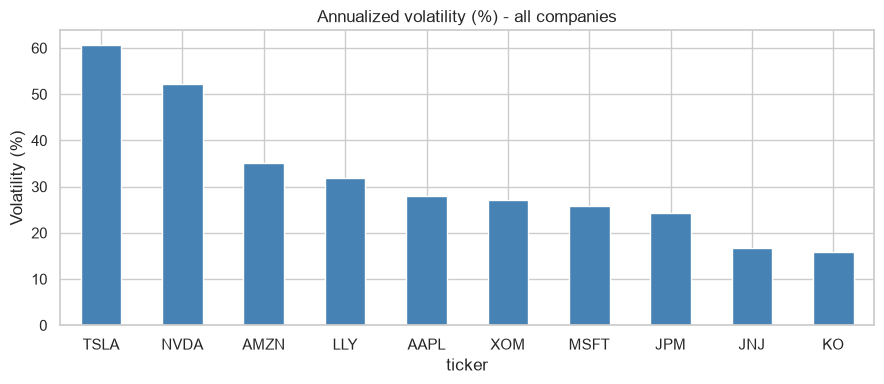

In [4]:
vol = pd.DataFrame({
    "daily_volatility": returns.std(),
    "annualized_volatility": returns.std() * np.sqrt(TRADING_DAYS),
}).sort_values("annualized_volatility", ascending=False)

display(vol.style.format("{:.2%}"))

ax = (vol["annualized_volatility"] * 100).plot(
    kind="bar", figsize=(9, 4), color="steelblue"
)
ax.set_title("Annualized volatility (%) - all companies")
ax.set_ylabel("Volatility (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Rolling volatility (63-day, about one quarter)

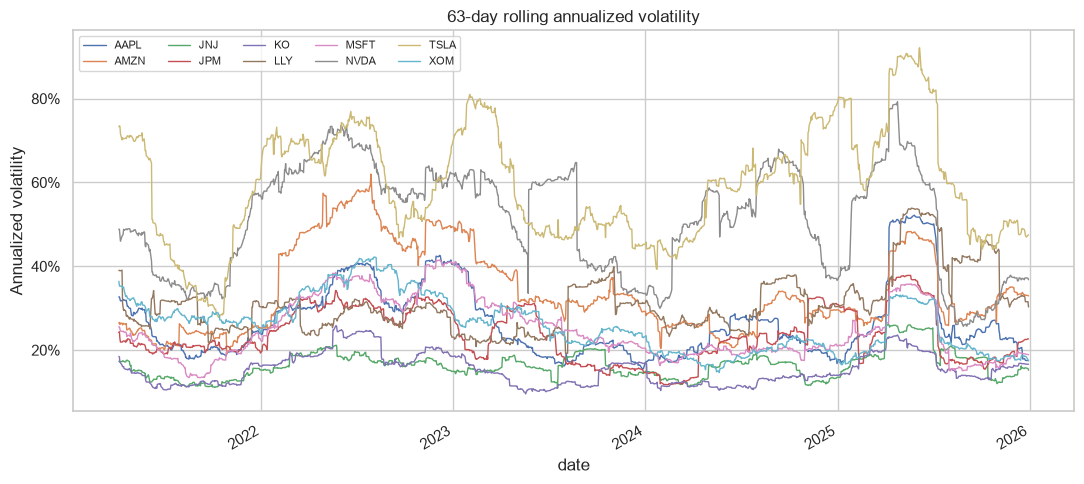

,min_rolling_vol,max_rolling_vol
ticker,,
TSLA,27.72%,92.13%
NVDA,25.67%,79.25%
AMZN,19.06%,61.99%
LLY,19.17%,53.87%
AAPL,15.52%,52.18%
XOM,14.64%,42.18%
MSFT,13.42%,41.46%
JPM,11.72%,37.83%
JNJ,10.91%,26.10%


In [5]:
rolling_vol = returns.rolling(63).std() * np.sqrt(TRADING_DAYS)

fig, ax = plt.subplots(figsize=(11, 5))
rolling_vol.plot(ax=ax, linewidth=1)
ax.set_title("63-day rolling annualized volatility")
ax.set_ylabel("Annualized volatility")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

# How unstable is each stock's risk over time?
vol_range = pd.DataFrame({
    "min_rolling_vol": rolling_vol.min(),
    "max_rolling_vol": rolling_vol.max(),
}).sort_values("max_rolling_vol", ascending=False)
display(vol_range.style.format("{:.2%}"))

## 4. Correlation

Pearson correlation of daily returns. Lower correlation between two stocks means more diversification benefit.

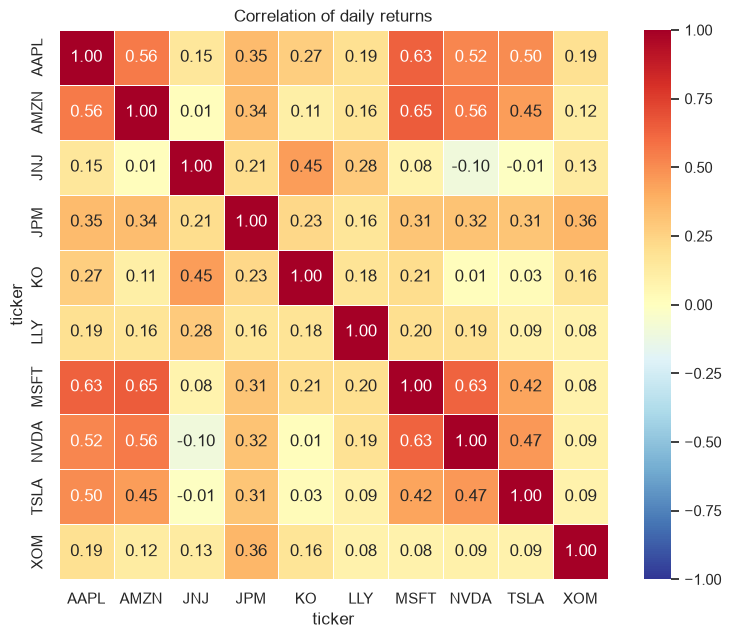

Top 5 most correlated pairs


,ticker_1,ticker_2,correlation
0,AMZN,MSFT,0.655
1,AAPL,MSFT,0.634
2,MSFT,NVDA,0.630
3,AAPL,AMZN,0.561
4,AMZN,NVDA,0.557


Top 5 least correlated pairs (best diversifiers)


,ticker_1,ticker_2,correlation
44,JNJ,NVDA,-0.098
43,JNJ,TSLA,-0.014
42,KO,NVDA,0.013
41,AMZN,JNJ,0.015
40,KO,TSLA,0.028


,avg_corr_with_others
ticker,
AAPL,0.374
MSFT,0.358
AMZN,0.331
NVDA,0.298
JPM,0.288
TSLA,0.260
KO,0.183
LLY,0.171
XOM,0.146


In [6]:
corr = returns.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation of daily returns")
plt.tight_layout()
plt.show()

# Pairwise ranking (upper triangle only, no self-pairs / duplicates)
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = (
    corr.where(mask).rename_axis(index="ticker_1", columns="ticker_2")
    .stack().dropna().rename("correlation").reset_index()
    .sort_values("correlation", ascending=False)
    .reset_index(drop=True)
)

print("Top 5 most correlated pairs")
display(pairs.head(5).style.format({"correlation": "{:.3f}"}))
print("Top 5 least correlated pairs (best diversifiers)")
display(pairs.tail(5).iloc[::-1].style.format({"correlation": "{:.3f}"}))

# Average correlation of each stock with all the others
avg_corr = ((corr.sum() - 1) / (len(corr) - 1)).rename("avg_corr_with_others")
display(avg_corr.sort_values(ascending=False).to_frame().style.format("{:.3f}"))

## 5. Maximum drawdown

Drawdown = percentage fall from the previous running peak of the closing price.
Maximum drawdown (MDD) is the worst such fall over the full period.

,max_drawdown,peak_date,trough_date,recovery_date,days_peak_to_trough,days_to_recover,current_drawdown
TSLA,-73.63%,2021-11-04 00:00:00,2023-01-03 00:00:00,2024-12-11 00:00:00,425,708,-7.24%
NVDA,-66.34%,2021-11-29 00:00:00,2022-10-14 00:00:00,2023-05-25 00:00:00,319,223,-9.41%
AMZN,-56.15%,2021-07-08 00:00:00,2022-12-28 00:00:00,2024-04-11 00:00:00,538,470,-8.45%
JPM,-38.77%,2021-10-22 00:00:00,2022-10-11 00:00:00,2023-12-14 00:00:00,354,429,-1.75%
MSFT,-37.15%,2021-11-19 00:00:00,2022-11-03 00:00:00,2023-06-15 00:00:00,349,224,-9.90%
LLY,-34.48%,2024-08-30 00:00:00,2025-08-08 00:00:00,2025-11-10 00:00:00,343,94,-2.72%
AAPL,-33.36%,2024-12-26 00:00:00,2025-04-08 00:00:00,2025-10-20 00:00:00,103,195,-4.58%
XOM,-20.51%,2022-06-08 00:00:00,2022-07-14 00:00:00,2022-10-19 00:00:00,36,97,0.00%
JNJ,-18.41%,2022-04-25 00:00:00,2023-10-27 00:00:00,2025-07-23 00:00:00,550,635,-3.39%
KO,-17.27%,2022-04-21 00:00:00,2023-10-05 00:00:00,2024-05-06 00:00:00,532,214,-3.50%


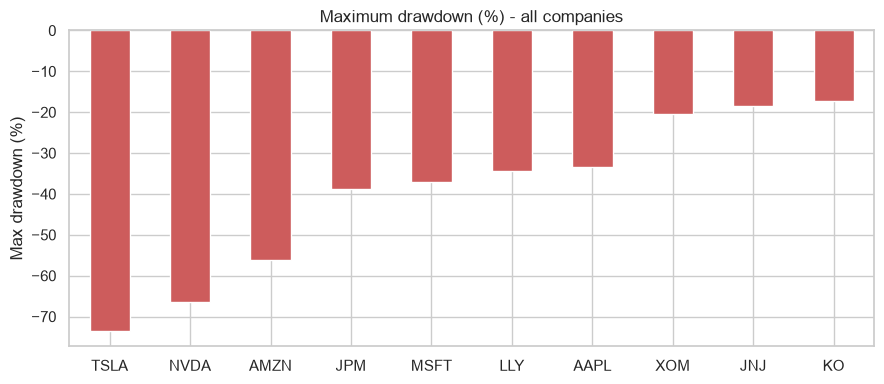

In [7]:
# Compute on prices from the first return date onward so it matches the return sample
prices_aligned = prices.loc[returns.index]

running_peak = prices_aligned.cummax()
drawdown = prices_aligned / running_peak - 1

def drawdown_details(price, dd):
    trough_date = dd.idxmin()
    peak_date = price.loc[:trough_date].idxmax()
    peak_price = price.loc[peak_date]
    after = price.loc[trough_date:]
    recovered = after[after >= peak_price]
    recovery_date = recovered.index[0] if len(recovered) else pd.NaT
    return pd.Series({
        "max_drawdown": dd.min(),
        "peak_date": peak_date,
        "trough_date": trough_date,
        "recovery_date": recovery_date,
        "days_peak_to_trough": (trough_date - peak_date).days,
        "days_to_recover": (recovery_date - trough_date).days if pd.notna(recovery_date) else np.nan,
        "current_drawdown": dd.iloc[-1],
    })

mdd = pd.DataFrame({t: drawdown_details(prices_aligned[t], drawdown[t]) for t in prices_aligned.columns}).T
mdd = mdd.sort_values("max_drawdown")
mdd["max_drawdown"] = mdd["max_drawdown"].astype(float)
mdd["current_drawdown"] = mdd["current_drawdown"].astype(float)

display(mdd.style.format({"max_drawdown": "{:.2%}", "current_drawdown": "{:.2%}"}))

ax = (mdd["max_drawdown"] * 100).plot(kind="bar", figsize=(9, 4), color="indianred")
ax.set_title("Maximum drawdown (%) - all companies")
ax.set_ylabel("Max drawdown (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

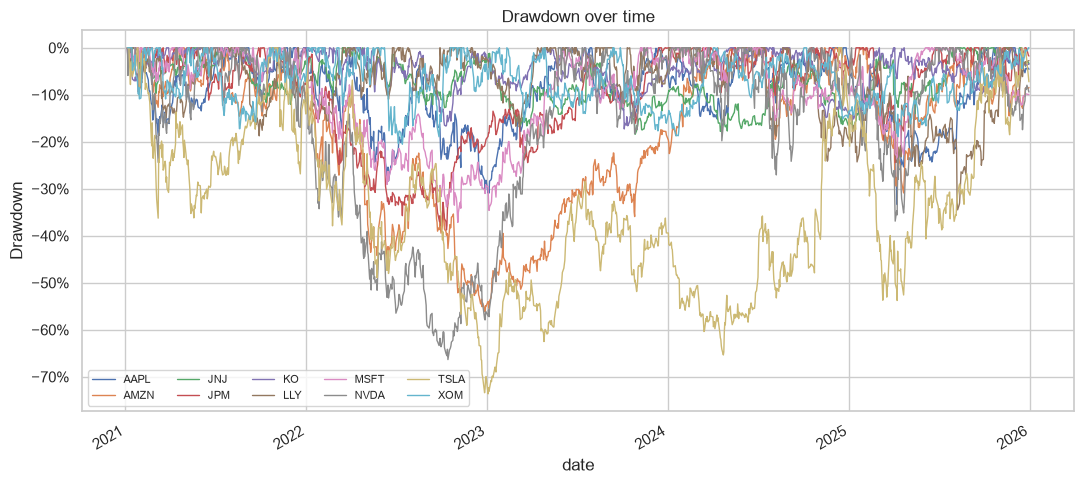

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
drawdown.plot(ax=ax, linewidth=1)
ax.set_title("Drawdown over time")
ax.set_ylabel("Drawdown")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

## 6. Combined risk summary

In [9]:
summary = pd.concat(
    [
        vol["annualized_volatility"],
        mdd["max_drawdown"],
        mdd["current_drawdown"],
        avg_corr,
    ],
    axis=1,
)
summary.columns = ["annualized_vol", "max_drawdown", "current_drawdown", "avg_corr_with_others"]

# Simple ranks: 1 = riskiest
summary["vol_rank"] = summary["annualized_vol"].rank(ascending=False).astype(int)
summary["mdd_rank"] = summary["max_drawdown"].rank(ascending=True).astype(int)
summary["avg_risk_rank"] = summary[["vol_rank", "mdd_rank"]].mean(axis=1)
summary = summary.sort_values("avg_risk_rank")

display(summary.style.format({
    "annualized_vol": "{:.2%}", "max_drawdown": "{:.2%}",
    "current_drawdown": "{:.2%}", "avg_corr_with_others": "{:.3f}",
    "avg_risk_rank": "{:.1f}",
}))

summary.to_csv("../../data/processed/risk_summary.csv")
corr.to_csv("../../data/processed/return_correlation.csv")
print("Saved: data/processed/risk_summary.csv, data/processed/return_correlation.csv")

,annualized_vol,max_drawdown,current_drawdown,avg_corr_with_others,vol_rank,mdd_rank,avg_risk_rank
TSLA,60.76%,-73.63%,-7.24%,0.260,1,1,1.0
NVDA,52.24%,-66.34%,-9.41%,0.298,2,2,2.0
AMZN,35.12%,-56.15%,-8.45%,0.331,3,3,3.0
LLY,31.97%,-34.48%,-2.72%,0.171,4,6,5.0
AAPL,27.87%,-33.36%,-4.58%,0.374,5,7,6.0
MSFT,25.72%,-37.15%,-9.90%,0.358,7,5,6.0
JPM,24.28%,-38.77%,-1.75%,0.288,8,4,6.0
XOM,27.03%,-20.51%,0.00%,0.146,6,8,7.0
JNJ,16.74%,-18.41%,-3.39%,0.134,9,9,9.0
KO,15.84%,-17.27%,-3.50%,0.183,10,10,10.0


Saved: data/processed/risk_summary.csv, data/processed/return_correlation.csv


## 7. Initial risk findings

In [10]:
hi, lo = vol.index[0], vol.index[-1]
worst, mildest = mdd.index[0], mdd.index[-1]
top_pair, bot_pair = pairs.iloc[0], pairs.iloc[-1]

print("INITIAL RISK FINDINGS")
print("=" * 60)
print(f"1. Highest volatility: {hi} ({vol.loc[hi, 'annualized_volatility']:.1%} annualized). "
      f"Lowest: {lo} ({vol.loc[lo, 'annualized_volatility']:.1%}).")
print(f"2. Deepest drawdown: {worst} ({mdd.loc[worst, 'max_drawdown']:.1%}, "
      f"{mdd.loc[worst, 'peak_date'].date()} -> {mdd.loc[worst, 'trough_date'].date()}). "
      f"Shallowest: {mildest} ({mdd.loc[mildest, 'max_drawdown']:.1%}).")
print(f"3. Most correlated pair: {top_pair.ticker_1}/{top_pair.ticker_2} ({top_pair.correlation:.2f}). "
      f"Best diversifying pair: {bot_pair.ticker_1}/{bot_pair.ticker_2} ({bot_pair.correlation:.2f}).")
print(f"4. Average pairwise correlation across all stocks: {pairs['correlation'].mean():.2f}. "
      f"Most 'market-like' stock: {avg_corr.idxmax()} ({avg_corr.max():.2f}); "
      f"most independent: {avg_corr.idxmin()} ({avg_corr.min():.2f}).")

not_recovered = mdd[mdd["recovery_date"].isna()].index.tolist()
print(f"5. Stocks that have not recovered from their worst drawdown: {not_recovered if not_recovered else 'none'}.")
still_down = summary[summary["current_drawdown"] < -0.10].index.tolist()
print(f"6. Stocks currently more than 10% below their peak: {still_down if still_down else 'none'}.")
print(f"7. Riskiest overall (avg of vol and drawdown rank): {summary.index[0]}. "
      f"Least risky: {summary.index[-1]}.")
print(f"8. Extreme daily moves (|return| > 20%): {int((returns.abs() > 0.20).sum().sum())}.")

INITIAL RISK FINDINGS
1. Highest volatility: TSLA (60.8% annualized). Lowest: KO (15.8%).
2. Deepest drawdown: TSLA (-73.6%, 2021-11-04 -> 2023-01-03). Shallowest: KO (-17.3%).
3. Most correlated pair: AMZN/MSFT (0.65). Best diversifying pair: JNJ/NVDA (-0.10).
4. Average pairwise correlation across all stocks: 0.25. Most 'market-like' stock: AAPL (0.37); most independent: JNJ (0.13).
5. Stocks that have not recovered from their worst drawdown: none.
6. Stocks currently more than 10% below their peak: none.
7. Riskiest overall (avg of vol and drawdown rank): TSLA. Least risky: KO.
8. Extreme daily moves (|return| > 20%): 3.


### Notes and next steps

- These are **preliminary** results based on daily closing prices and full-sample statistics.
- Volatility and drawdown are backward-looking; correlations tend to rise in market stress, so full-sample correlation can understate crisis-period risk.
- Next: Value at Risk / Expected Shortfall, beta vs a market index, rolling and stress-period correlation, and portfolio-level risk.